### Region of interest (ROI) cropping
Crop images to focus on the main object, discarding background margins and artifacts

(1024, 512)


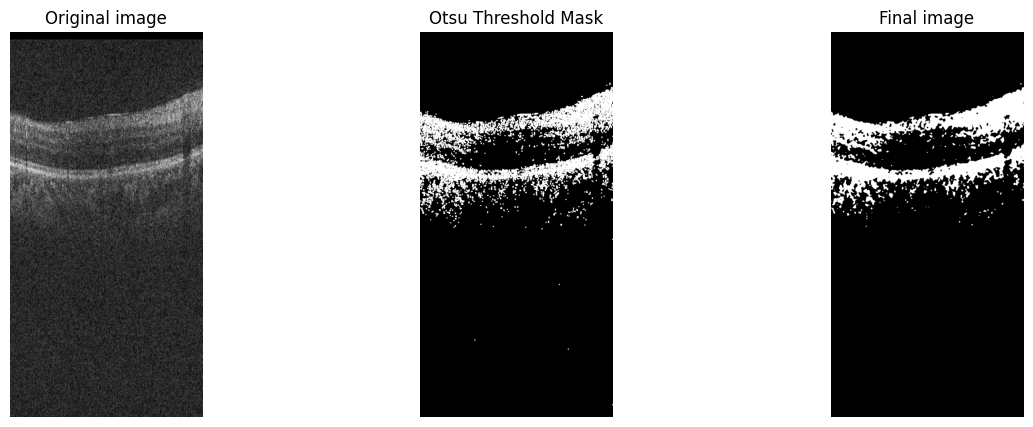

In [ ]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from src.utils.preprocessing import get_image_background_borders

def preprocess_RESC_image(image_path):
    img_pil = Image.open(image_path)
    img_original = np.array(img_pil)
    print(img_original.shape)
    if img_original is None:
        print("Error: Image not found.")
        return
    
    # --- Otsu's Thresholding ---
    # This automatically finds the best threshold value to separate background from foreground
    threshold_val, img_otsu = cv2.threshold(
        img_original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Removes small "salt and pepper" noise from the thresholded mask
    kernel = np.ones((3,3), np.uint8)
    img_otsu = cv2.morphologyEx(img_otsu, cv2.MORPH_OPEN, kernel)
    img_final = cv2.medianBlur(img_otsu, 5)

    # Visualization
    titles = ['Original image', 'Otsu Threshold Mask', 'Median filter (Final image)']
    images = [img_original, img_otsu, img_final]

    plt.figure(figsize=(15, 5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(images[i], 'gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

    return img_final

# Usage
mask = preprocess_RESC_image("/media/vhondru/hdd/istoian/BMAD/dataset/RESC/train/good/5.png")

(1024, 512)
(1024, 512)


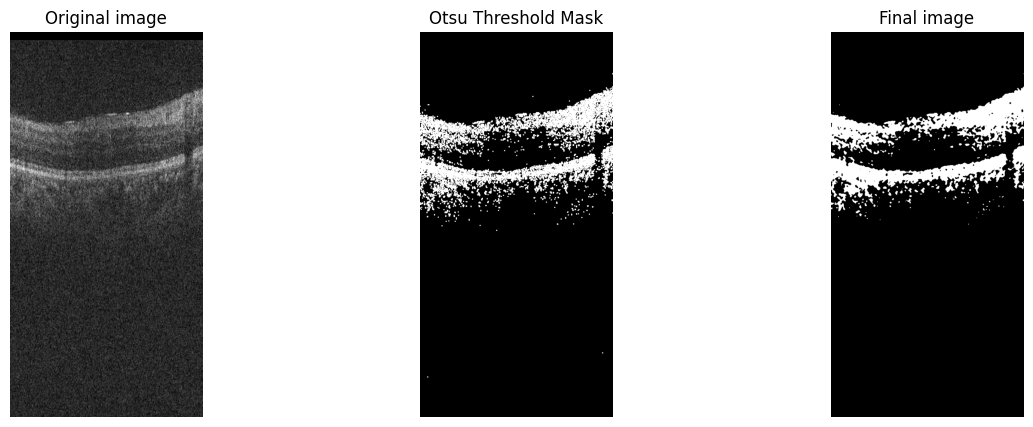

Cropped image size:  (511, 421)
After cropping: 


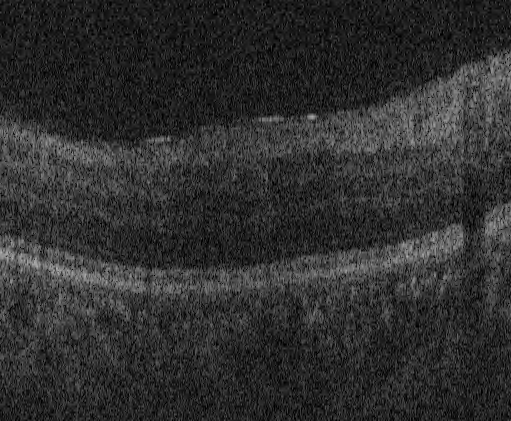

In [9]:
img_path = "/media/vhondru/hdd/istoian/BMAD/dataset/RESC/train/good/3.png"
image = Image.open(img_path).convert("L")
image_arr = np.array(image)
print(image_arr.shape)
preprocessed_img = preprocess_RESC_image(img_path)
borders_dict = get_image_background_borders(image_arr=preprocessed_img, count_border_pixels=10)
image = image.crop(box=(borders_dict["left"], borders_dict["top"], borders_dict["right"], borders_dict["bottom"]))
print("Cropped image size: ", image.size)

print("After cropping: ")
image

In [ ]:
brain_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/BraTS2021_slice/train/good/", "*"))
img_pil = Image.open(brain_image_paths[5])
img_original = np.array(img_pil)
img_original.shape


(240, 240, 4)

In [11]:
liver_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/hist_DIY/train/good/", "*"))
img_pil = Image.open(liver_image_paths[5])
img_original = np.array(img_pil)
img_original.shape

(512, 512)

In [12]:
img_pil = Image.open(liver_image_paths[5]).convert("RGB")
img_original = np.array(img_pil)
print(img_original.shape)

print(np.sum(img_original, axis=(0, 1)))

(512, 512, 3)
[2537971 2537971 2537971]


In [13]:
resc_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/RESC/train/good/", "*"))
img_pil = Image.open(resc_image_paths[5])
img_original = np.array(img_pil)
img_original.shape

(1024, 512)

In [14]:
img_pil = Image.open(resc_image_paths[5]).convert("RGB")
img_original = np.array(img_pil)
print(img_original.shape)

print(np.sum(img_original, axis=(0, 1)))

(1024, 512, 3)
[18996261 18996261 18996261]


In [15]:
hist_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/OCT2017/train/good/", "*"))
img_pil = Image.open(hist_image_paths[5])
img_original = np.array(img_pil)
img_original.shape

(496, 768, 3)

In [16]:
chest_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/Chest-RSNA/train/good/", "*"))
img_pil = Image.open(chest_image_paths[5])
img_original = np.array(img_pil)
img_original.shape

(1024, 1024)

In [17]:
camelyon_image_paths = glob.glob(os.path.join("/media/vhondru/hdd/istoian/BMAD/dataset/camelyon16_256/train/good/", "*"))
img_pil = Image.open(camelyon_image_paths[5])
img_original = np.array(img_pil)
img_original.shape

(256, 256, 3)